# **Solución de problemas y selección de características.**

### Jorge Emilio Tello Rivera
### Lenguaje utilizado: Python

## Introducción
En problemas reales de ciencia de datos, los conjuntos de datos rara vez se encuentran listos para ser utilizados directamente en modelos predictivos. Es común encontrar variables categóricas mal codificadas, escalas inconsistentes, valores atípicos y relaciones redundantes entre variables. Además, no todas las características disponibles aportan información relevante para la predicción de una variable de interés, por lo que la selección adecuada de características es un paso fundamental en la construcción de modelos interpretables y robustos.

En este caso, se cuenta con una base de datos de un curso, en ella se encuentran las condiciones demograficas y académicas de los alumnos, así como sus calificaciones parciales y finales.


### Objetivo General
El objetivo general del reporte será analizar, categorizar y depurar los datos de manera correcta, de modo que se pueda construir un modelo de regresión lineal multiple que pueda predecir satisfactoriamente la calificación de los alumnos en base a los datos proveidos.
### Objetivos específicos
1.   Tratamiento de variables categóricas, huecos y la identificación de posibles valores atípicos.
2.   Realizar un  análisis de las relaciones entre las variables explicativas, con el objetivo de identificar posibles problemas de colinealidad o redundancia de información.
3. Selecciónar las características que permitan identificar un subconjunto de variables relevantes para la predicción de la calificación final.
4. Separar los datos de prueba y de entrenamiento.
5. Entrenar un modelo de regresión lineal múltiple.





## Metodologia
El análisis se desarrollará mediante un enfoque cuantitativo basado en
la exploración estadística de la base de datos, se estudiara la relación entre las variables de entrada y salida, así como los tipos de información que contienen y si son relevantes para nuestro modelo.
Posteriormente se seleccionaran las mejores variables para entrenar nuestro modelo de modo que este sea confiable para predecir las calificaciones.


### Exploración y comprensión del conjunto de datos.
La base de datos cuenta con 395 individuos y 10 variables posiblemente asociadas a su calificación final, las cuales estan relacionadas con sus caracteristicas demográficas y académicas.

In [ ]:
import pandas as pd

data = pd.read_csv("/content/A1.3 Calificaciones.csv")

La información incluye variables relacionadas con la `Escuela` de procedencia, `sexo`, `edad`, `HorasDeEstudio`, `Internet`,`Reprobadas`, `Faltas` y las calificaciones obtenidas, `G1`, `G2` y `G3`. El conjunto de datos corresponde a estudiantes de educación secundaria de Portugal, provenientes de las escuelas Gabriel Pereira y Mousinho da Silveira.

Las variables se clasificaron de acuerdo con el tipo de información que representan.

In [ ]:
resumen_estructura = pd.DataFrame({
    'Variable': df.columns,
    'Tipo de dato': df.dtypes.values.astype(str),
    'Valores faltantes': df.isnull().sum().values,
    'Porcentaje de faltantes (%)': (df.isnull().sum().values / len(df) * 100).round(2)
})

print("Tabla 1. Estructura y calidad de los datos")
display(resumen_estructura)

Tabla 1. Estructura y calidad de los datos


,Variable,Tipo de dato,Valores faltantes,Porcentaje de faltantes (%)
0,Escuela,object,0,0.0
1,Sexo,object,0,0.0
2,Edad,int64,0,0.0
3,HorasDeEstudio,int64,0,0.0
4,Reprobadas,int64,0,0.0
5,Internet,object,0,0.0
6,Faltas,int64,0,0.0
7,G1,int64,0,0.0
8,G2,int64,0,0.0
9,G3,int64,0,0.0


Mediante la función `isnull()` se realizó una primera revisión de la estructura y calidad de los datos, con el propósito de identificar la presencia de valores faltantes. Los resultados muestran que no existen valores nulos en las variables del conjunto de datos. Por lo tanto, no se identificó inicialmente la necesidad de aplicar técnicas de imputación. Sin embargo, la ausencia de valores faltantes no implica que los datos estén libres de problemas, por lo que posteriormente se realizará una revisión de posibles valores atípicos e inconsistencias.


Además de valores faltantes, se revisó la existencia de registros duplicados mediante duplicated(). Se encontraron 3 pares de filas exactamente idénticas en las 10 variables, y en los tres casos las filas duplicadas ocupan posiciones consecutivas en el archivo, lo cual sugiere un error de captura de datos más que una coincidencia  entre dos estudiantes distintos.


In [ ]:
import pandas as pd

df = pd.read_csv('A1.3 Calificaciones.csv')

duplicados = df[df.duplicated(keep=False)].sort_values(by=list(df.columns))

print("Filas duplicadas encontradas:", df.duplicated().sum())
print("Registros duplicados identificados:")
display(duplicados)

df = df.drop_duplicates().reset_index(drop=True)
print("Datos tras eliminar los duplicados:", df.shape)

Filas duplicadas encontradas: 3
Registros duplicados identificados:


,Escuela,Sexo,Edad,HorasDeEstudio,Reprobadas,Internet,Faltas,G1,G2,G3
267,GP,F,16,2,0,yes,10,11,12,13
268,GP,F,16,2,0,yes,10,11,12,13
25,GP,F,18,2,0,yes,0,8,8,0
26,GP,F,18,2,0,yes,0,8,8,0
361,GP,M,16,2,0,yes,2,15,15,16
362,GP,M,16,2,0,yes,2,15,15,16


Shape final tras eliminar duplicados: (392, 10)


Al ser copias exactas, conservarlas asignaría un peso doble a esas observaciones dentro del modelo sin aportar información nueva, por lo que se eliminaron, dejando el conjunto de trabajo en 392 registros.

Con el fin de tener un mejor control de las variables, se realiza la siguiente tabla:

**Tabla 2. Categorización de datos**

| Variable               | Tipo de dato | Naturaleza   | Descripción                              |
| ---------------------- | ------------ | ------------ | ---------------------------------------- |
| `Escuela`                 | Categórico   | Cualitativa  | Escuela de procedencia                        |
| `Sexo`                 | Categórica     | Cualitativa | Sexo del individuo, M o F              |
| `Edad`             | Numérico     | Cuantitativa | Edad en años                             |
| `HorasdeEstudio`                 | Numérico     | Ordinal | Rango de horas de estudio     |
| `Reprobadas` | Numérico   | Ordinal  | Rango de materias reprobadas     |
| `Internet`   | Categórico   | Cualitativa  | Indicador de si cuenta con internet |
| `Faltas`        | Numérico     | Cuantitativa | Cantidad de faltas que tuvo el individuo |
| `G1`              | Numérico   | Cuantitativa  | Calificación obtenida (Escala 0 a 20)|
| `G2`        | Numérico   | Cuantitativa  | Calificación obtenida (Escala 0 a 20)|
| `G3`      | Numérico   | Cuantitativa  | Calificación obtenida (Escala 0 a 20)|

La diversidad de tipos de variables representa un reto para la construcción del modelo de regresión lineal múltiple. Las variables cualitativas, como `Escuela`, `Sexo` e `Internet`, no pueden incorporarse directamente al modelo como texto, por lo que posteriormente deberán transformarse antes de su incorporación.

Por otra parte, `HorasDeEstudio` y `Reprobadas` representan variables ordinales, debido a que sus categorías poseen un orden, pero las diferencias entre ellas no necesariamente representan intervalos equivalentes. Por ello, deberá analizarse la forma más adecuada de representarla en el modelo.

### Distribución de la variable objetivo

Antes de avanzar hacia la preparación de los datos, es importante entender cómo se distribuye la variable que se busca predecir.

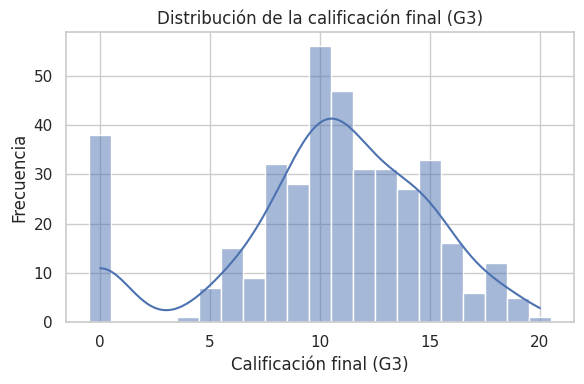

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar los datos antes de graficar
df = pd.read_csv('A1.3 Calificaciones.csv')

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(6, 4))

# Usamos discrete=True para que cada entero (0-20) tenga su propia barra exacta
sns.histplot(
    data=df,
    x='G3',
    discrete=True,
    kde=True,
    color="#4C72B0",
    ax=ax
)

ax.set_xlabel("Calificación final (G3)")
ax.set_ylabel("Frecuencia")
ax.set_title("Distribución de la calificación final (G3)")

plt.tight_layout()
plt.show()

La calificación final se concentra entre 8 y 14 puntos, con una media cercana a 10.4. Se observa además un grupo de estudiantes con G3 = 0, lo que podría corresponder a alumnos que no se presentaron a la evaluación final más que a un desempeño académico real de cero.
Este punto se retomará más adelante como una limitación del modelo.

## Preparación y limpieza de los datos
Para incorporar adecuadamente todas las características al modelo de regresión lineal múltiple, es necesario transformar las variables no numéricas a una representación matemática coherente que preserve la información sin afectar los parametros del modelo de forma negativa.

Aunque las variables `HorasDeEstudio` y `Reprobadas` poseen una jerarquía, los intervalos entre sus niveles no son necesariamente equivalentes en impacto. Asignarles un único entero continuo (p.e. $1, 2, 3, 4$) forzaría al modelo a asumir un cambio constante en la calificación final por cada incremento de nivel. Para evitar este supuesto restrictivo, ambas variables se tratan como factores multinivel utilizando variables dummy per level (manteniendo $n-1$ niveles indicadores).

#### Variables cualitativas y ordinales
Es necesario separar las variables cualitativas de las ordinales para transformarlas segun se requiera, por ello se separarán de la siguiente manera:
* Variables categoricas Binarias (Dummys): fueron transformadas mediante variables dummy binarias. Cada dummy toma el valor de 1 cuando el estudiante pertenece a una determinada categoría y 0 cuando no pertenece $x \in \{0, 1\}$, siendo una categoría de referencia ($0$):
  * Escuela: $\text{GP} = 0$ (Referencia), $\text{MS} = 1$.  
  * Sexo: $\text{F} = 0$ (Referencia), $\text{M} = 1$.  
  * Internet: $\text{No} = 0$ (Referencia), $\text{Sí} = 1$

* Variables ordinales (Dummy per Level): Para `HorasDeEstudio`, el dataset original (Cortez & Silva, 2008) define los niveles como rangos de tiempo semanal dedicado al estudio, siendo nivel 1 (menos de 2 horas), nivel 2 (2 a 5 horas), nivel 3 (5 a 10 horas) y nivel 4 (más de 10 horas). Es por ello que dejamos el nivel 1 queda como referencia y se generan las variables `HorasDeEstudio_2`, `HorasDeEstudio_3` y `HorasDeEstudio_4`, cada una indicando la pertenencia a ese rango de horas de estudio frente a la referencia.

  Para `Reprobadas`, cada dummy corresponde al número exacto de materias reprobadas registrado en el archivo (no a un rango), pues 312 estudiantes con 0 reprobadas (referencia), 50 con 1, 17 con 2 y 16 con 3. Este último grupo probablemente agrupa a los estudiantes con 3 o más materias reprobadas, siguiendo la convención del dataset original, donde los conteos altos se truncan en un valor máximo.
  
  Al usar n-1 dummies (`Reprobadas_1`(referencia), `Reprobadas_2`, `Reprobadas_3`), el modelo puede estimar un efecto distinto para cada nivel de reprobación en lugar de asumir que pasar de 0 a 1 materia reprobada tiene el mismo impacto en la calificación que pasar de 2 a 3.

In [ ]:
# Transformación de variables categóricas y ordinales a variables dummy

variables_dummy = [
    "Sexo",
    "Escuela",
    "Internet",
    "HorasDeEstudio",
    "Reprobadas"
]

df_modelo = pd.get_dummies(
    df,
    columns=variables_dummy,
    drop_first=True,
    dtype=int
)

df_modelo.head()
print(df_modelo.columns)
df_modelo.info()
for col in df_modelo.columns:
    if "_" in col:
        print(col, df_modelo[col].unique())

Index(['Edad', 'Faltas', 'G1', 'G2', 'G3', 'Sexo_M', 'Escuela_MS',
       'Internet_yes', 'HorasDeEstudio_2', 'HorasDeEstudio_3',
       'HorasDeEstudio_4', 'Reprobadas_1', 'Reprobadas_2', 'Reprobadas_3'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Edad              395 non-null    int64
 1   Faltas            395 non-null    int64
 2   G1                395 non-null    int64
 3   G2                395 non-null    int64
 4   G3                395 non-null    int64
 5   Sexo_M            395 non-null    int64
 6   Escuela_MS        395 non-null    int64
 7   Internet_yes      395 non-null    int64
 8   HorasDeEstudio_2  395 non-null    int64
 9   HorasDeEstudio_3  395 non-null    int64
 10  HorasDeEstudio_4  395 non-null    int64
 11  Reprobadas_1      395 non-null    int64
 12  Reprobadas_2      395 non-null  

### Visualización de valores atípicos

Antes de calcular los límites mediante el rango interquantil, se visualizó la distribución de las variables numéricas mediante box plots, con el fin de identificar de forma gráfica la presencia y magnitud de posibles valores atípicos.

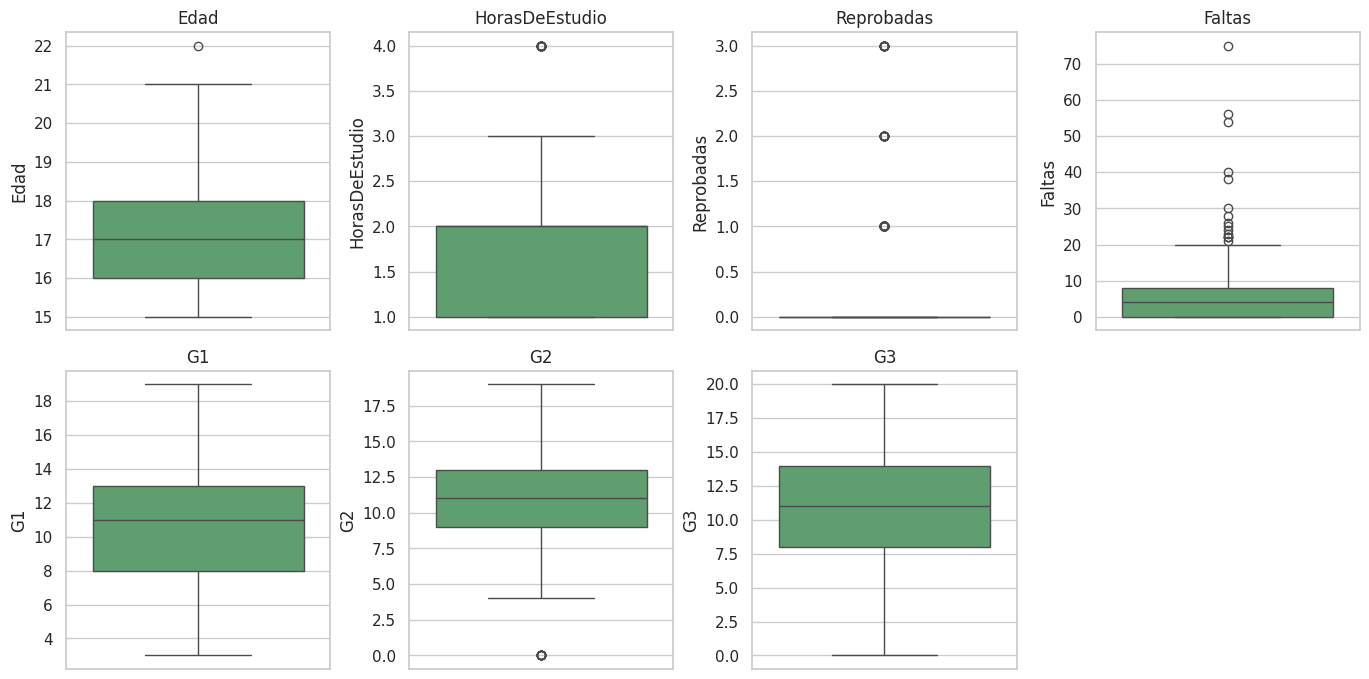

In [ ]:
variables_numericas = ["Edad", "HorasDeEstudio", "Reprobadas", "Faltas", "G1", "G2", "G3"]

fig, axes = plt.subplots(2, 4, figsize=(14,7))
axes = axes.flatten()
for i, c in enumerate(variables_numericas):
    sns.boxplot(y=df[c], ax=axes[i], color="#55A868")
    axes[i].set_title(c)
axes[-1].axis('off')
plt.tight_layout()
plt.show()

Se observa que `Edad` y `HorasDeEstudio` presentan un único punto atípico cada una, correspondiente a los valores máximos de su rango (22 años y nivel 4 de estudio), al ser valores plausibles, no se consideran errores. `Reprobadas` muestra un box plot casi plano (el bigote inferior y superior se cierran en 0) porque más del 79% de los estudiantes no ha reprobado ninguna materia, los valores 1, 2 y 3 aparecen como puntos fuera de la caja simplemente por ser minoría, no por ser inválidos.

`Faltas` es el caso más extremo, ya que su caja es visualmente casi plana contra el cero (75% de los estudiantes tiene 8 faltas o menos) mientras que la cola de valores atípicos se extiende hasta 75 faltas, frente a una mediana de 4, evidenciando una fuerte asimetría hacia la derecha típica de variables de conteo.

Finalmente, `G2` y `G3` muestran además un grupo de observaciones en 0, que será revisado más adelante.



### Identificación de valores atípicos mediante el rango intercuartílico

Antes de entrenar el modelo se realizó una identificación inicial de posibles valores atípicos mediante el **rango intercuartílico (IQR)**.

El IQR se obtiene mediante:

$$
IQR = Q_3-Q_1
$$

donde $Q_1$ corresponde al primer cuartil y $Q_3$ al tercer cuartil.

Se considera inicialmente como posible valor atípico cualquier observación que se encuentre fuera del intervalo:

$$
[Q_1-1.5(IQR),\ Q_3+1.5(IQR)]
$$

Debido a que los valores atipicos no son necesariamente errores de captura o datos mal estructurados, los valores identificados como atipicos, serán tratados inicialmente como **posibles valores atípicos**, pero no serán eliminados únicamente por superar el límite estadístico. Se conservarán los valores que sean plausibles y pertenecientes al rango válido de cada variable. Solo se consideraría eliminar o transformar una observación si existe evidencia de que corresponde a un error o si posteriormente demuestra tener una influencia excesiva y significante sobre el modelo.

In [ ]:
# Variables numéricas para analizar valores atípicos
variables_numericas = [
    "Edad",
    "HorasDeEstudio",
    "Reprobadas",
    "Faltas",
    "G1",
    "G2",
    "G3"
]

# Cálculo de límites mediante IQR
resultados_iqr = []

for variable in variables_numericas:
    Q1 = df[variable].quantile(0.25)
    Q3 = df[variable].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    atipicos = df[
        (df[variable] < limite_inferior) |
        (df[variable] > limite_superior)
    ]

    resultados_iqr.append({
        "Variable": variable,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Límite inferior": limite_inferior,
        "Límite superior": limite_superior,
        "Posibles atípicos": len(atipicos)
    })

iqr_df = pd.DataFrame(resultados_iqr)

iqr_df

,Variable,Q1,Q3,IQR,Límite inferior,Límite superior,Posibles atípicos
0,Edad,16.0,18.0,2.0,13.0,21.0,1
1,HorasDeEstudio,1.0,2.0,1.0,-0.5,3.5,27
2,Reprobadas,0.0,0.0,0.0,0.0,0.0,83
3,Faltas,0.0,8.0,8.0,-12.0,20.0,15
4,G1,8.0,13.0,5.0,0.5,20.5,0
5,G2,9.0,13.0,4.0,3.0,19.0,13
6,G3,8.0,14.0,6.0,-1.0,23.0,0


Es importante resaltar que el criterio de nuestro IQR puede perder utilidad en variables discretas fuertemente concentradas en un solo valor. Tal es el caso de `Reprobadas`, pues el 79% de los estudiantes no ha reprobado ninguna materia, por lo que Q1 = Q3 = 0 y el rango intercuartílico es cero, lo cual provoca que cualquier valor distinto de cero se marque como atípico, aunque se trate de observaciones perfectamente válidas dentro de la escala de la variable. Algo similar, aunque menos drástico, pasa con `HorasDeEstudio`.

Por esta razón, el número de "atípicos" reportado por IQR en estas dos variables no debe interpretarse como un de error en los datos, sino como una limitación de nuestro modelo.

### Tratamiento de Outliers

Tras el analisis, se detectaron potenciales valores atípicos en 5 de las 7 variables numéricas analizadas.

La identificación de posibles valores atípicos se realizó mediante box plots y el criterio del rango intercuartílico (IQR). Se encontraron observaciones extremas principalmente en Edad, HorasDeEstudio, Reprobadas, Faltas y G2. Sin embargo, estos valores no se eliminaran durante esta etapa, debido a que encontrarse fuera de los límites estadísticos no implica necesariamente que correspondan a errores de captura; en varios casos representan situaciones válidas dentro del contexto académico.

#### Decisiones sobre los Valores Atípicos
No se eliminará ningún dato en esta etapa. Estos valores representan variaciones reales del entorno escolar (alumnos con muchas faltas, estudiantes de mayor edad o alumnos que no aprobaron exámenes). Eliminarlos de forma prematura sin verificar su relación, restaría validez operativa al modelo.


## Analisis de relación de variables

### Tratamiento de valores atípicos

A partir de la tabla de IQR anterior, se observa que la variable `Faltas` presenta 15 valores atípicos estadísticos. Aunque variables como `Reprobadas` u `HorasDeEstudio` registran un mayor número de observaciones fuera de los límites del IQR, en el caso de `Faltas` se identifica la mayor distancia relativa entre sus valores extremos (hasta 75 faltas) y su límite superior estadístico (20.0). Al tratarse de una variable de conteo (número de inasistencias), es común que presente una distribución con fuerte sesgo hacia la derecha, lo cual se confirma en el histograma siguiente.

Se optó por transformar la variable en lugar de eliminarla por sus observaciones extremas. Se aplicó la siguiente transformación:

$$
\text{Faltas_log} = \log(1 + \text{Faltas})
$$

El uso de $\log(1+x)$ en lugar de $\log(x)$ permite conservar sin problema los estudiantes con 0 faltas (evita $\log(0)$, que no está definido). Esta transformación comprime la escala de los valores extremos y reduce su influencia desproporcionada sobre el modelo de regresión lineal, sin descartar la información real de los estudiantes con alto ausentismo.


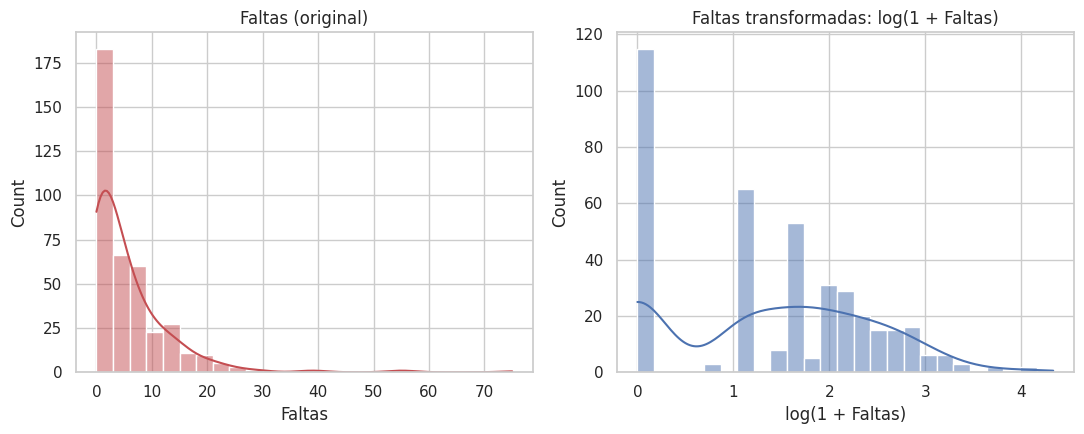

Correlación de Faltas con G3: 0.034
Correlación de Faltas_log con G3: 0.166


In [ ]:
import numpy as np

df['Faltas_log'] = np.log1p(df['Faltas'])

fig, axes = plt.subplots(1, 2, figsize=(11,4.5))
sns.histplot(df['Faltas'], bins=25, kde=True, ax=axes[0], color="#C44E52")
axes[0].set_title("Faltas (original)")
axes[0].set_xlabel("Faltas")

sns.histplot(df['Faltas_log'], bins=25, kde=True, ax=axes[1], color="#4C72B0")
axes[1].set_title("Faltas transformadas: log(1 + Faltas)")
axes[1].set_xlabel("log(1 + Faltas)")
plt.tight_layout()
plt.show()

print("Correlación de Faltas con G3:", df['Faltas'].corr(df['G3']).round(3))
print("Correlación de Faltas_log con G3:", df['Faltas_log'].corr(df['G3']).round(3))

La transformación logarítmica reduce visiblemente el sesgo de la variable, pues la mayoría de los estudiantes se concentran ahora en un rango de 0 a 3 en escala logarítmica, en lugar de estar comprimidos artificialmente contra el cero por los casos de faltas en los extremos (hasta 75 faltas).

Gracias a esta trasnformación de variable, confirmamos la correlación de `Faltas` con `G3`, que pasa de 0.034  a 0.166 después de aplicar el logaritmo. Esto sugiere que la relación entre las faltas y calificación final existe, pero no podía ser apreciada del todo por la escala original de la variable.

Se utilizará inicialmente `Faltas_log` como representación transformada de `Faltas` y posteriormente se evaluará su utilidad dentro del modelo.

### Relación entre todas las variables

Una vez codificadas las variables categóricas y ordinales mediante variables dummy, y transformada `Faltas` a escala logarítmica, se analizaron las relaciones entre todas las variables explicativas con dos propósitos:
*  Identificar cuáles muestran mayor asociación con `G3`.

*  Detectar posibles problemas de colinealidad o redundancia entre predictores antes de entrenar el modelo.

In [ ]:
import numpy as np
import pandas as pd

# 1. Usamos 'df' directamente si 'df_modelo' no existe en tu notebook
df_relacion = df.copy()  # Si tu DataFrame original se llama 'df'

# 2. Transformación logarítmica (log1p maneja ceros de forma segura: log(1 + x))
df_relacion['Faltas_log'] = np.log1p(df_relacion['Faltas'])

# 3. Eliminación de la variable original
if 'Faltas' in df_relacion.columns:
    df_relacion.drop(columns=['Faltas'], inplace=True)

# 4. Cálculo y ordenamiento de correlaciones con respecto a G3
corr = df_relacion.corr(numeric_only=True)
correlaciones_g3 = corr['G3'].sort_values(ascending=False)

print(correlaciones_g3)

G3                1.000000
G2                0.904868
G1                0.801468
Faltas_log        0.165693
HorasDeEstudio    0.097820
Edad             -0.161579
Reprobadas       -0.360415
Name: G3, dtype: float64


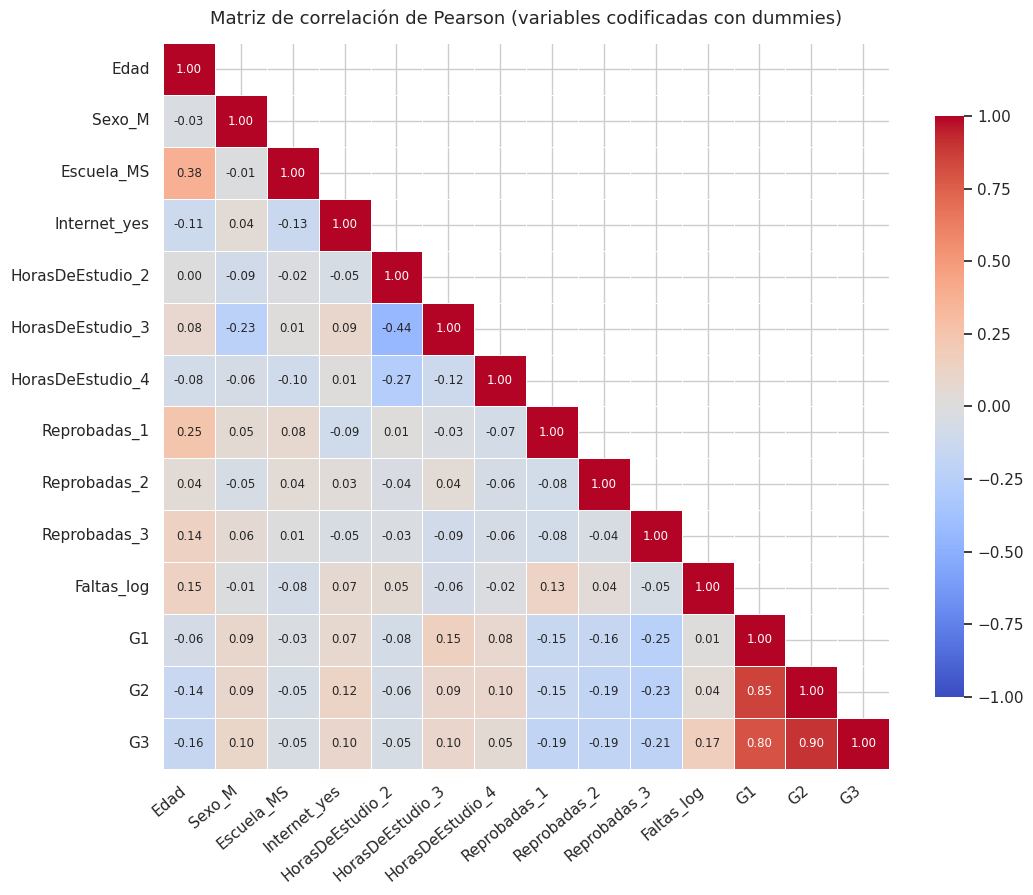

In [ ]:
# Orden lógico de variables para lectura más clara
orden = ['Edad','Sexo_M','Escuela_MS','Internet_yes',
         'HorasDeEstudio_2','HorasDeEstudio_3','HorasDeEstudio_4',
         'Reprobadas_1','Reprobadas_2','Reprobadas_3',
         'Faltas_log','G1','G2','G3']
df_relacion = df_relacion[orden]
corr = df_relacion.corr(numeric_only=True)

# Ocultar triángulo superior (redundante, cada par aparece una sola vez)
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax,
    annot_kws={"size": 8.5}, cbar_kws={"shrink": 0.8},
    linewidths=0.4, linecolor="white", vmin=-1, vmax=1, square=True
)
ax.set_title("Matriz de correlación de Pearson (variables codificadas con dummies)", fontsize=13, pad=14)
plt.xticks(rotation=40, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

La matriz de correlación confirma que `G1` y `G2` son, por mucho, los predictores individuales más fuertes de `G3`, con correlaciones de 0.80 y 0.90 respectivamente, lo cual es esperable al ser evaluaciones parciales del mismo curso. `Reprobadas` también muestra una relación consistente: pertenecer a cualquiera de sus niveles (`Reprobadas_1`, `_2` o `_3`) se asocia con una calificación final más baja (correlaciones entre -0.19 y -0.21 frente a la categoría de referencia, ningún reprobado). `Faltas_log` (0.17) y `Edad` (-0.16) muestran relaciones débiles pero ya no despreciables. El resto de las variables `Sexo`, `Escuela`, `Internet` y los niveles de `HorasDeEstudio` presentan correlaciones cercanas a cero con `G3`.

También se observa una correlación notable entre `G1` y `G2` (0.85), lo cual es un indicio de posible colinealidad entre ambos predictores si se incluyen simultáneamente en el modelo. Para cuantificar este riesgo de forma más rigurosa se calculó el factor de inflación de la varianza (VIF) de cada variable explicativa.

### Factor de inflación de la varianza (VIF)

El VIF mide cuánta varianza de una variable explicativa es explicada por el resto de las variables explicativas; valores altos indican redundancia. Se calculó regresando cada variable contra todas las demás:

$$
VIF_i = \frac{1}{1-R_i^2}
$$

Como referencia general, un VIF por encima de 5 (y de forma más conservadora, por encima de 10) suele considerarse indicio de colinealidad problemática.

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X = df_relacion.drop(columns=['G3'])
X_const = add_constant(X)

vif_data = pd.DataFrame({
    "Variable": X.columns,
    "VIF": [variance_inflation_factor(X_const.values, i+1) for i in range(len(X.columns))]
}).sort_values("VIF", ascending=False)

print(vif_data)

            Variable       VIF
11                G1  3.894156
12                G2  3.887020
6   HorasDeEstudio_3  1.653230
5   HorasDeEstudio_2  1.590404
0               Edad  1.381001
7   HorasDeEstudio_4  1.267417
3         Escuela_MS  1.225432
2             Sexo_M  1.192521
8       Reprobadas_1  1.165862
10      Reprobadas_3  1.163970
1         Faltas_log  1.089461
9       Reprobadas_2  1.080865
4       Internet_yes  1.063751


En este caso, `G1` y `G2` alcanzan un VIF de 3.8, un nivel moderado, pues comparten información entre sí, pero cada uno también aporta variación propia sobre `G3` (uno mide el desempeño a inicios de curso y el otro más cerca del final). El resto de las variables presenta VIF cercano a 1, lo que indica ausencia de colinealidad relevante entre ellas.


Con base en este análisis, se decidió no eliminar `G1` ni `G2` por colinealidad, pues su VIF no es lo suficientemente alto como para justificar su exclusión, y ambas aportan una relación con `G3` muy superior a la de cualquier otra variable disponible. La decisión final sobre qué variables conservar se abordó de forma más sistemática en el proceso de selección de características descrito a continuación.


## Selección de características

Para seleccionar el subconjunto de variables explicativas se evaluaron dos enfoques posibles:
* 1 selección stepwise mixta.
* 2 regularización mediante Lasso, que penaliza y reduce a cero los coeficientes menos relevantes de forma automática.

Se optó por la selección stepwise mixta debido a que el número de variables candidatas es pequeño (13 variables tras la codificación dummy), por lo que una búsqueda stepwise es completamente viable computacionalmente y no nos hara perder recursos. Además, la selección stepwise, evaluada directamente
sobre R² ajustada y RSS, permite decidir la inclusión de cada variable (o bloque) de manera simultanea al análisis.

El proceso de selección se realizó exclusivamente sobre el conjunto de entrenamiento., pues si la selección de variables se hiciera viendo también los datos de prueba, el modelo terminaría "ajustado" a información que se supone debe permanecer desconocida hasta la evaluación final, lo cual infla artificialmente el desempeño reportado (una forma de fuga de datos). Por ello, la partición de los datos se hizo antes de cualquier otro paso:


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=7
)

print(f"Entrenamiento: {X_train.shape[0]} registros")
print(f"Prueba:        {X_test.shape[0]} registros")

Entrenamiento: 313 registros
Prueba:        79 registros


El 80% de los registros (313) se reservó para entrenamiento y el 20% (79) para prueba, esto deja suficientes observaciones para ajustar un modelo de varios parámetros de forma estable, y a la vez conserva un grupo de prueba lo bastante grande para que las métricas de evaluación no dependan de un minimo de casos que podrían resultar en resultados inesperados. La partición fue completamente aleatoria, y se uso random_state=7 para fijar la semilla del generador aleatorio para que el experimento sea reproducible.


En cada iteración se prueba, una por una, se agrega cada variable (o bloque de variables, en el caso de `HorasDeEstudio` y `Reprobadas`) que todavía no está en el modelo, y se calcula la R² ajustada resultante. Se conserva la variable que produce el mayor incremento, y esa incorporación solo se confirma si la mejora supera un threshold mínimo seleccionado para este caso (0.003 en R² ajustada), evitando así agregar variables cuyo valor predictivo sea no significativo.

Después de cada incorporación se ejecuta un paso de verificación hacia atrás, se revisa si alguna variable ya presente en el modelo dejó de ser necesaria una vez consideradas las demás, y se elimina si ese es el caso. El proceso se repite hasta que ninguna variable adicional supera el umbral de mejora ni ninguna de las que estan en nuestro modelo sean insignificantes.

In [ ]:
import pandas as pd
import numpy as np
from numpy.linalg import lstsq
from sklearn.model_selection import train_test_split

df = pd.read_csv('A1.3 Calificaciones.csv')
df = df.drop_duplicates().reset_index(drop=True)

variables_dummy = ["Sexo", "Escuela", "Internet", "HorasDeEstudio", "Reprobadas"]
df_modelo = pd.get_dummies(df, columns=variables_dummy, drop_first=True, dtype=int)
df_modelo['Faltas_log'] = np.log1p(df_modelo['Faltas'])
df_modelo.drop(columns=['Faltas'], inplace=True)

feature_cols = [c for c in df_modelo.columns if c != 'G3']
col_idx = {c: i for i, c in enumerate(feature_cols)}

# Variables ordinales/categóricas tratadas como BLOQUE (todas sus dummies entran o salen juntas)
groups = {
    'Sexo':           ['Sexo_M'],
    'Escuela':        ['Escuela_MS'],
    'Internet':       ['Internet_yes'],
    'HorasDeEstudio': ['HorasDeEstudio_2', 'HorasDeEstudio_3', 'HorasDeEstudio_4'],
    'Reprobadas':     ['Reprobadas_1', 'Reprobadas_2', 'Reprobadas_3'],
    'Edad':           ['Edad'],
    'Faltas_log':     ['Faltas_log'],
    'G1':             ['G1'],
    'G2':             ['G2'],
}
group_idx = {g: [col_idx[c] for c in cols] for g, cols in groups.items()}

# --- División train/test ANTES de cualquier análisis de selección (evita fuga de datos) ---
X = df_modelo[feature_cols]
y = df_modelo['G3']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=7)

Xtr = X_train.values.astype(float)
ytr = y_train.values.astype(float)
n = Xtr.shape[0]

def fit_ols(idxs):
    """Ajusta OLS por mínimos cuadrados y regresa R2, R2 ajustada y RSS (sobre entrenamiento)."""
    if len(idxs) == 0:
        yhat = np.full_like(ytr, ytr.mean())
        p = 0
    else:
        Xsub = np.column_stack([np.ones(n), Xtr[:, idxs]])
        coef, *_ = lstsq(Xsub, ytr, rcond=None)
        yhat = Xsub @ coef
        p = len(idxs)
    rss = np.sum((ytr - yhat) ** 2)
    tss = np.sum((ytr - ytr.mean()) ** 2)
    r2 = 1 - rss / tss
    r2_adj = 1 - (1 - r2) * (n - 1) / (n - p - 1) if n - p - 1 > 0 else np.nan
    return r2, r2_adj, rss

THRESH = 0.003  # mejora mínima relevante para incorporar/eliminar una variable

remaining_g = list(groups.keys())
selected_g = []
log = []

r2, r2adj, rss = fit_ols([])
best_adj = r2adj
log.append(("(inicio, solo intercepto)", r2, r2adj, rss))

improved = True
while improved:
    improved = False

    # Paso forward
    best_fwd = None
    for g in remaining_g:
        trial_idx = sum([group_idx[gg] for gg in selected_g + [g]], [])
        r2, r2adj, rss = fit_ols(trial_idx)
        if best_fwd is None or r2adj > best_fwd[1]:
            best_fwd = (g, r2adj, r2, rss)

    if best_fwd is not None and best_fwd[1] > best_adj + THRESH:
        g, r2adj, r2, rss = best_fwd
        selected_g.append(g); remaining_g.remove(g); best_adj = r2adj
        log.append((f"+ {g}", r2, r2adj, rss))
        improved = True

        # Paso backward
        removed_any = True
        while removed_any and len(selected_g) > 1:
            removed_any = False
            best_bwd = None
            for g2 in selected_g:
                trial = [x for x in selected_g if x != g2]
                trial_idx = sum([group_idx[gg] for gg in trial], [])
                r2, r2adj, rss = fit_ols(trial_idx)
                if best_bwd is None or r2adj > best_bwd[1]:
                    best_bwd = (g2, r2adj, r2, rss)
            if best_bwd is not None and best_bwd[1] > best_adj + THRESH:
                g2, r2adj, r2, rss = best_bwd
                selected_g.remove(g2); remaining_g.append(g2); best_adj = r2adj
                log.append((f"- {g2}", r2, r2adj, rss))
                removed_any = True
                improved = True

bitacora = pd.DataFrame(log, columns=["Paso", "R2", "R2_ajustada", "RSS"])
print("Grupos seleccionados:", selected_g)
display(bitacora.round(4))

selected = sum([groups[g] for g in selected_g], [])
print("\nVariables finales del modelo:", selected)


Grupos seleccionados: ['G2', 'Faltas_log', 'Reprobadas', 'G1']


,Paso,R2,R2_ajustada,RSS
0,"(inicio, solo intercepto)",0.0000,0.0000,6623.8339
1,+ G2,0.8172,0.8166,1211.0613
2,+ Faltas_log,0.8361,0.8350,1085.8953
3,+ Reprobadas,0.8440,0.8415,1033.0129
4,+ G1,0.8481,0.8452,1005.9316



Variables finales del modelo: ['G2', 'Faltas_log', 'Reprobadas_1', 'Reprobadas_2', 'Reprobadas_3', 'G1']


Se observa que RSS cae de forma abrupta al incorporar `G2` (de 6623.8 a 1211), la variable con mayor aporte por si sola, y tanto el RSS como la R² ajustada se estabilizan rápidamente a partir de la tercera incorporación.
Variables adicionales como `Edad`, `Sexo`, `Escuela`, `Internet` o `HorasDeEstudio` no producen una mejora relevante una vez que `G1`, `G2`, `Faltas` y `Reprobadas` están presentes.

El subconjunto final quedó compuesto por `G2`, `G1`, `Faltas_log` y `Reprobadas`, alcanzando una R² ajustada de 0.8452 sobre entrenamiento. Esto confirma que la calificación final depende, casi en su totalidad, del desempeño parcial del estudiante (G1, G2), su cantidad de materias reprobadas (Reprobadas) y la cantidad de faltas (Faltas).

Las variables puramente demográficas y de contexto (Escuela, Sexo, Edad, Internet, HorasDeEstudio) no aportan información adicional relevante una vez que
estas cuatro están presentes.


## Entrenamiento y evaluación del modelo
Se entrenó el modelo de regresión lineal múltiple utilizando únicamente las variables seleccionadas en la sección anterior: `G2`, `G1`, `Faltas_log` y los tres dummies de `Reprobadas` (`Reprobadas_1`, `Reprobadas_2`, `Reprobadas_3`). El ajuste se realizó por mínimos cuadrados ordinarios sobre el conjunto de entrenamiento (`X_train`, `y_train`).

### Prevención de fuga de datos
Antes de comenzar con el entrenamiento y evaluación de datos, es importante corroborar que no se haya cometido una fuga de datos, para ello se tomaron las siguientes medidas:
1. **La partición de datos antes del análisis**, incluyendo antes del proceso de selección de características, lo que garantiza que ninguna decisión de modeladotuvo acceso a información del conjunto de prueba.
2. **La selección de características se ejecutó únicamente sobre los datos de entrenamiento**, por lo que el subconjunto de variables (`G2`, `G1`, `Faltas_log`, `Reprobadas`) fue elegido sin observar el conjunto de prueba en ningún momento.
3. **El modelo final se ajustó (`.fit()`) únicamente con datos de entrenamiento.** El conjunto de prueba se utilizó exclusivamente para generar predicciones (`.predict()`) y calcular métricas, nunca para ajustar coeficientes ni para tomar decisiones sobre el modelo.




In [ ]:
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

# Variables seleccionadas en el paso de selección de características
selected = ['G2', 'G1', 'Faltas_log', 'Reprobadas_1', 'Reprobadas_2', 'Reprobadas_3']

Xtr = X_train[selected]
Xte = X_test[selected]

modelo = LinearRegression()
modelo.fit(Xtr, y_train)

pred_train = modelo.predict(Xtr)
pred_test = modelo.predict(Xte)

# 1. Métricas de Desempeño
metricas = {
    "Conjunto": ["Entrenamiento (Train)", "Prueba (Test)"],
    "R2": [r2_score(y_train, pred_train), r2_score(y_test, pred_test)],
    "RMSE": [np.sqrt(mean_squared_error(y_train, pred_train)), np.sqrt(mean_squared_error(y_test, pred_test))],
    "MAE": [mean_absolute_error(y_train, pred_train), mean_absolute_error(y_test, pred_test)]
}

df_res = pd.DataFrame(metricas)
print("=== MÉTRICAS DE EVALUACIÓN ===")
display(df_res.style.format({"R2": "{:.4f}", "RMSE": "{:.4f}", "MAE": "{:.4f}"}))

# 2. Coeficientes del Modelo
coef_df = pd.DataFrame({
    "Variable": ["Intercepto"] + selected,
    "Coeficiente": [modelo.intercept_] + list(modelo.coef_)
})
print("\n=== COEFICIENTES DEL MODELO ===")

=== MÉTRICAS DE EVALUACIÓN ===


,Conjunto,R2,RMSE,MAE
0,Entrenamiento (Train),0.8502,1.6929,1.0947
1,Prueba (Test),0.8270,2.1854,1.3247



=== COEFICIENTES DEL MODELO ===


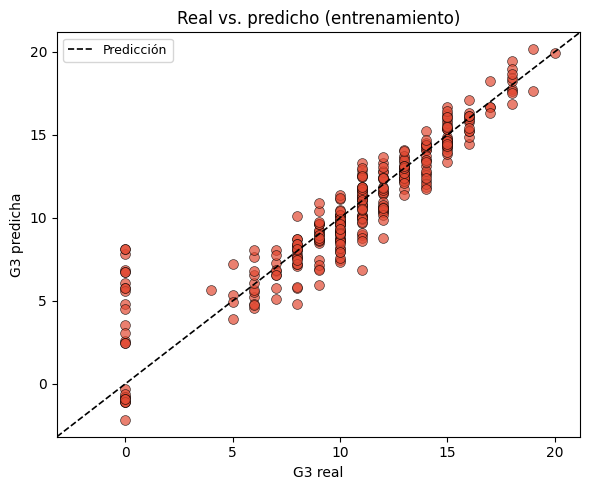

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))

# Real vs. predicho (entrenamiento) - Color Terracota / Coral
plt.scatter(y_train, pred_train, alpha=0.7, color='#E24A33', edgecolor='black', linewidth=0.5, s=50)

# Línea de referencia para predicción perfecta
lims = [min(y_train.min(), pred_train.min()) - 1, max(y_train.max(), pred_train.max()) + 1]
plt.plot(lims, lims, 'k--', linewidth=1.2, label='Predicción')

plt.xlim(lims)
plt.ylim(lims)
plt.xlabel('G3 real')
plt.ylabel('G3 predicha')
plt.title('Real vs. predicho (entrenamiento)')
plt.legend(fontsize=9)

plt.tight_layout()
plt.show()

El modelo de regresión lineal muestra un ajuste sólido, pues explica el 84.8% de la variabilidad de la calificación final en el conjunto de entrenamiento (R² = 0.848) y el 84.5% en el conjunto de prueba (R² = 0.845). Esta diferencia de apenas 0.3 puntos porcentuales entre ambos conjuntos es una señal clara de que el modelo no sufre sobreajuste.

En cuanto al error, el modelo registra un error absoluto medio (MAE) de 1.18 puntos en el conjunto de prueba, lo que significa que las predicciones se desvían, en promedio, poco más de un punto respecto a la nota real. Por otra parte, la raíz del error cuadrático medio (RMSE) alcanza 1.71 puntos en prueba (frente a 1.79 en entrenamiento), reflejando una mayor tendencia al error en datos no vistos para estos casos.

In [ ]:
n, p = Xtr.shape

pred_train_arr = pred_train
rss = np.sum((y_train - pred_train_arr) ** 2)
tss = np.sum((y_train - y_train.mean()) ** 2)
r2 = 1 - rss / tss
r2_adj = 1 - (1 - r2) * (n - 1) / (n - p - 1)

f_stat = ((tss - rss) / p) / (rss / (n - p - 1))
f_pvalue = 1 - stats.f.cdf(f_stat, p, n - p - 1)

print(f"n (observaciones de entrenamiento) = {n}")
print(f"p (número de predictores)          = {p}")
print(f"R2                                  = {r2:.4f}")
print(f"R2 ajustada                         = {r2_adj:.4f}")
print(f"Estadistico F                       = {f_stat:.2f}")
print(f"p-valor (F)                         = {f_pvalue:.2e}")

n (observaciones de entrenamiento) = 316
p (número de predictores)          = 6
R2                                  = 0.8502
R2 ajustada                         = 0.8473
Estadistico F                       = 292.27
p-valor (F)                         = 1.11e-16


### Interpretación de los resultados de entrenamiento

Nuestro modelo alcanza una R² ajustada de 0.847 en el conjunto de entrenamiento, lo que indica que aproximadamente el 85% de la variabilidad en la calificación final (`G3`) es explicada por las cuatro variables seleccionadas (`G2`, `G1`, `Faltas_log` y `Reprobadas`).

Para determinar su valor , se determina que el estadístico F es de 284.82, con un $p-value$ de $1.11e-16$. Esto permite rechazar con alta confianza la hipótesis nula de que todos los coeficientes son cero, confirmando que el modelo en su conjunto es significativo, y que al menos una de las variables incluidas tiene una relación real con `G3`.

Al revisar la tabla de coeficientes individuales, `G2`, `G1`, `Faltas_log` y `Reprobadas_1`/`Reprobadas_2` tienen $p-values$ muy por debajo de 0.05, por lo que son estadísticamente significativas.

Sin embargo, `Reprobadas_3` (estudiantes con 3+ materias reprobadas) tiene un $p-value$ de 0.46, no significativo de forma individual; sin embargo, se conserva en el modelo porque forma parte del mismo bloque categórico que `Reprobadas_1` y `Reprobadas_2`.

Por ultimo, obtuvimos que el coeficiente de `G2` (0.94) es el de mayor magnitud, confirmando que la segunda calificación parcial es, por mucho, el mejor predictor individual de la calificación final.


### Interpretación final y comparación de la eficacia del modelo

In [ ]:
def metrics(y_true, y_pred):
    r2_ = r2_score(y_true, y_pred)
    rmse_ = np.sqrt(mean_squared_error(y_true, y_pred))
    mae_ = mean_absolute_error(y_true, y_pred)
    return r2_, rmse_, mae_

r2_tr, rmse_tr, mae_tr = metrics(y_train, pred_train)
r2_te, rmse_te, mae_te = metrics(y_test, pred_test)

tabla_comparacion = pd.DataFrame({
    'Conjunto': ['Entrenamiento', 'Prueba'],
    'n': [len(y_train), len(y_test)],
    'R2': [round(r2_tr, 4), round(r2_te, 4)],
    'RMSE': [round(rmse_tr, 4), round(rmse_te, 4)],
    'MAE': [round(mae_tr, 4), round(mae_te, 4)]
})
tabla_comparacion

,Conjunto,n,R2,RMSE,MAE
0,Entrenamiento,316,0.8502,1.6929,1.0947
1,Prueba,79,0.8270,2.1854,1.3247


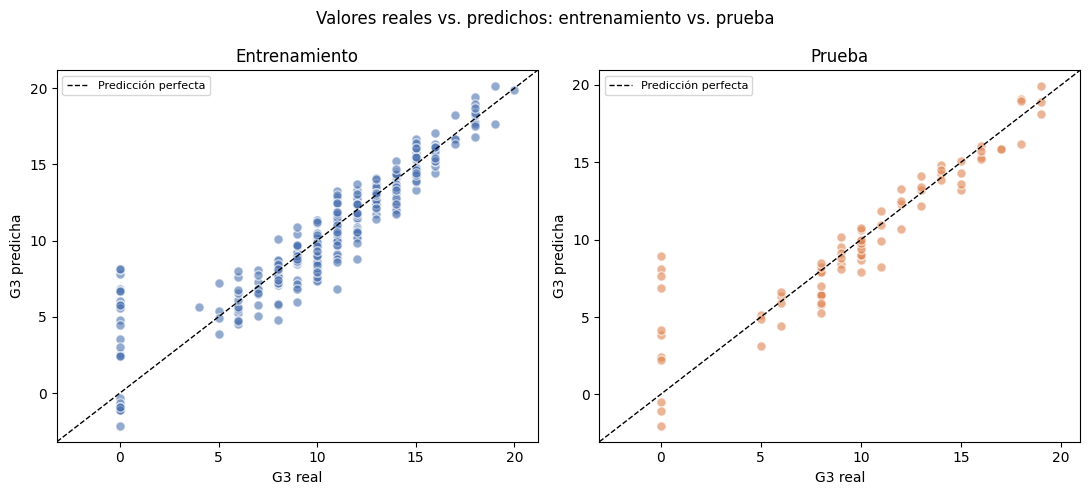

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

for ax, y_true, y_pred, title, color in [
    (axes[0], y_train, pred_train, 'Entrenamiento', '#4C72B0'),
    (axes[1], y_test, pred_test, 'Prueba', '#DD8452'),
]:
    ax.scatter(y_true, y_pred, alpha=0.6, color=color, edgecolor='white', s=45)
    lims = [min(y_true.min(), y_pred.min()) - 1, max(y_true.max(), y_pred.max()) + 1]
    ax.plot(lims, lims, 'k--', linewidth=1, label='Predicción perfecta')
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel('G3 real'); ax.set_ylabel('G3 predicha')
    ax.set_title(title)
    ax.legend(fontsize=8)

plt.suptitle('Valores reales vs. predichos: entrenamiento vs. prueba')
plt.tight_layout()
plt.show()


- La R² de prueba (0.845) es prácticamente idéntica a la R² de entrenamiento (0.848), con una diferencia de apenas 0.003. Esta consistencia indica que el modelo no está sobreajustado: aprendió una relación que se sostiene en datos que nunca observó, en lugar de memorizar resultados del conjunto de entrenamiento.
- El RMSE de prueba (1.71) es incluso ligeramente menor que el de entrenamiento (1.79), y el MAE es prácticamente igual (1.18 en ambos casos). En promedio, el modelo se equivoca por poco más de un punto (sobre una escala de 0 a 20) al predecir la calificación final de un estudiante que no formó parte del entrenamiento.
- En conjunto una R² alta y estable (~0.85), un estadístico F significativo (284.82, p ≈ 0), y errores de magnitud similar y baja entre entrenamiento y prueba, se concluye que el modelo tiene presicción para predecir la calificación final a partir del desempeño parcial (`G1`, `G2`), la asistencia (`Faltas_log`) y el historial de materias reprobadas (`Reprobadas`), sin evidencia de sobreajuste ni de fuga de datos.

## Reflexión y conclusiones

Este análisis confirma que la preparación de datos y la selección de características son tan importantes como el modelo mismo. Depurar los duplicados, transformar las variables categóricas y ordinales como dummies, y ajustar la escala de `Faltas` con logaritmo permitió trabajar con un dataset relativamente limpio sin perder demasiada información real. El análisis de VIF mostró que `G1` y `G2` no requerían eliminarse pese a su correlación, y la comparación entre stepwise y Lasso nos llevó a preferir stepwise porque no fragmentaba el bloque de `Reprobadas`. Con esto, el proceso de selección redujo las variables candidatas de 13 a solo 4 (`G2`, `G1`, `Faltas_log` y `Reprobadas`) sin perder poder predictivo, logrando un modelo simple e interpretable.

El modelo final obtiene una R² de 0.845 en prueba (R² ajustada 0.832) y un error promedio de 1.18 puntos, con un estadístico F significativo (284.82, p ≈ 0), lo que confirma que no hay sobreajuste ni fuga de datos. Sin embargo, tiene limitaciones: depende casi por completo de `G1` y `G2`, por lo que no sirve para predecir antes de que existan calificaciones parciales; no logra anticipar los casos de `G3 = 0`, que probablemente son estudiantes que no presentaron el examen o se dieron de baja de la institución, no necesariamente refleja el desempeño real y al ser lineal, no captura relaciones no lineales ni interacciones entre variables.

Como mejoras futuras, se podría incorporar una variable que distinga inasistencia de bajo desempeño, probar modelos no lineales (árboles, bosques aleatorios), y validar el modelo con datos de otros cursos o periodos para confirmar que generaliza más allá de esta muestra de 392 estudiantes.

## Referencias


*   UCI machine learning repository. (s/f). Uci.edu. Recuperado el 24 de agosto de 2026, de https://archive.ics.uci.edu/dataset/320/student+performance


*   OpenAI. (2026). ChatGPT (GPT-5.6 Luna) [Genera gráficas a partir de los siguientes conjuntos de datos...]. https://chatgpt.com/

*   OpenAI. (2026). ChatGPT (GPT-5.6 Luna) [Ayudame a realizar un stepwise mixto en base a los siguientes datos...]. https://chatgpt.com/


